# Sentiment Analysis of Indonesian Reviews with RNN and LSTM

**Course:** Deep Learning, Fundamental Aspects of RNN and LSTM (implementation)

This notebook applies a **Recurrent Neural Network (SimpleRNN)** and a **Long Short-Term Memory (LSTM)** network to a real problem: automatically reading Indonesian customer reviews and deciding whether each one is **positive, neutral or negative**.

We train both models on the same data so we can see in practice what the theory said: an LSTM keeps information over long sequences better than a plain RNN, because of the vanishing gradient problem.

**Notebook outline**
1. The problem
2. The data
3. Exploring the data
4. Preparing the text (turning words into sequences)
5. Building the SimpleRNN and LSTM models
6. Training (cross-entropy loss + Backpropagation Through Time)
7. Evaluation and comparison
8. Long reviews vs short reviews (vanishing gradient in practice)
9. Trying the model on new reviews
10. Conclusion

## 1. The problem

Indonesian businesses such as restaurants, hotels, online shops and app developers receive thousands of reviews and comments every day on platforms like Google Maps, TripAdvisor, Tokopedia and the Play Store. Reading them one by one is not possible, but the business still needs to know:

- Are customers happy or unhappy this week?
- Which reviews are complaints that need a quick reply?
- Did a new menu, price or app update change how people feel?

**Task:** given the text of a review, predict its sentiment: `negative`, `neutral` or `positive`. This is a **many-to-one** sequence problem: a sequence of words goes in, and one label comes out at the end.

**Why a recurrent network?** A review is **sequential data**: the meaning depends on the order of the words.

| Review | Sentiment |
|---|---|
| *makanannya enak* (the food is tasty) | positive |
| *makanannya **tidak** enak* (the food is **not** tasty) | negative |
| *tempatnya bagus **tapi** pelayanannya lambat* (nice place **but** slow service) | depends on the whole sentence |

A bag-of-words model or a plain feedforward network treats these words as an unordered set. An RNN reads them **one by one, in order**, and carries a memory (the hidden state $h_t$) from word to word, so *"tidak"* can change the meaning of *"enak"* that comes after it.

## 2. The data

We use **SmSA (Sentiment Analysis on Indonesian reviews)**, one of the tasks in the **IndoNLU benchmark** (Wilie et al., 2020). The data was originally collected by Prosa.ai (Purwarianti & Crisdayanti, 2019) from Indonesian online reviews and comments, such as restaurant reviews and comments about public figures, and labelled by hand.

| Split in the original dataset | Rows | Used here as |
|---|---|---|
| `train_preprocess.tsv` | 11,000 | 90% training, 10% validation |
| `valid_preprocess.tsv` | 1,260 | **test set** (never seen during training) |
| `test_preprocess_masked_label.tsv` | 500 | not used: its labels are hidden for the benchmark leaderboard |

Each row has two columns: the review text (already lower-cased, with punctuation separated by spaces) and its label.

Source: https://github.com/IndoNLP/indonlu (dataset folder `smsa_doc-sentiment-prosa`).

In [ ]:
# ---- Setup ----
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
keras.utils.set_random_seed(SEED)   # same random start every run, so results are reproducible
sns.set_theme(style="whitegrid")

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [ ]:
# ---- Load the SmSA data straight from the IndoNLU GitHub repository ----
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"

def load_tsv(name):
    return pd.read_csv(BASE_URL + name, sep="\t", header=None, names=["text", "label"],
                       quoting=csv.QUOTE_NONE)   # some reviews contain quote marks, so read them as plain text

train_full = load_tsv("train_preprocess.tsv")
test_df    = load_tsv("valid_preprocess.tsv")     # the official validation split = our test set

print("Training data:", train_full.shape)
print("Test data    :", test_df.shape)
train_full.head()

Training data: (11000, 2)
Test data    : (1260, 2)


,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai...,neutral
2,lokasi strategis di jalan sumatera bandung . t...,positive
3,betapa bahagia nya diri ini saat unboxing pake...,positive
4,duh . jadi mahasiswa jangan sombong dong . kas...,negative


## 3. Exploring the data

Before building a model, we check two things:
1. **How balanced are the classes?** If one class dominates, the model can look accurate just by always guessing that class.
2. **How long are the reviews?** This decides the sequence length the RNN must handle. Long sequences are exactly where vanishing gradients become a problem.

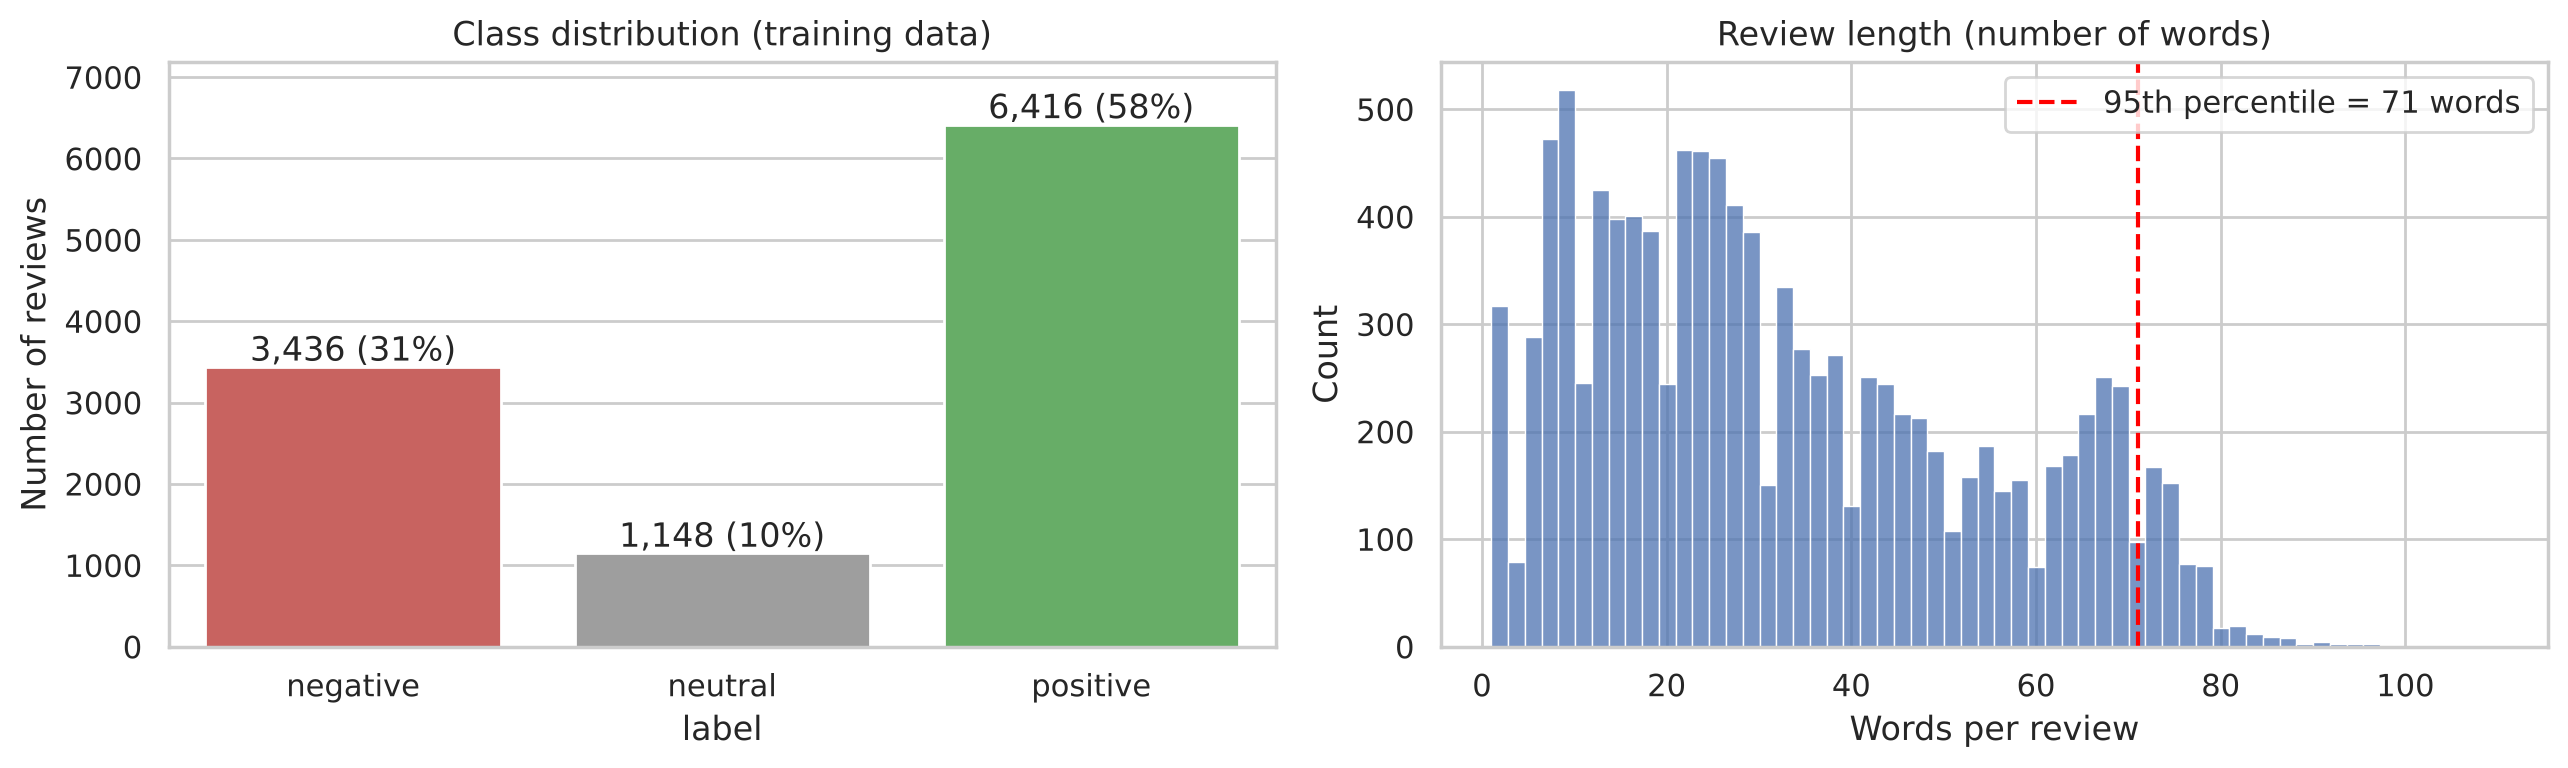

count    11000.0
mean        32.9
std         21.2
min          1.0
25%         16.0
50%         28.0
75%         48.0
max        110.0
Name: n_words, dtype: float64


In [ ]:
ORDER = ["negative", "neutral", "positive"]
for df in (train_full, test_df):
    df["n_words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = train_full["label"].value_counts().reindex(ORDER)
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=["#d9534f", "#9e9e9e", "#5cb85c"], hue=counts.index, legend=False)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 80, f"{v:,} ({v / counts.sum():.0%})", ha="center")
axes[0].set_title("Class distribution (training data)")
axes[0].set_ylabel("Number of reviews")
axes[0].set_ylim(0, counts.max() * 1.12)

sns.histplot(train_full["n_words"], bins=60, ax=axes[1])
p95 = np.percentile(train_full["n_words"], 95)
axes[1].axvline(p95, color="red", linestyle="--", label=f"95th percentile = {p95:.0f} words")
axes[1].set_title("Review length (number of words)")
axes[1].set_xlabel("Words per review")
axes[1].legend()
plt.tight_layout()
plt.show()

print(train_full["n_words"].describe().round(1))

In [ ]:
# A few examples from each class
for label in ORDER:
    print(f"=== {label.upper()} ===")
    for t in train_full[train_full.label == label].sample(2, random_state=SEED)["text"]:
        print("-", t[:200] + ("..." if len(t) > 200 else ""))
    print()

=== NEGATIVE ===
- kita akhir pekan ke sana . sesak dan antre . beli voucher makan dulu . dari beberapa makanan yang kita coba , mahal dan tidak ada yang enak . habis itu sisa voucher tidak bisa diuangkan kembali , pada...
- oh pantesan dipecat dari menteri . sudah ada kjp kok ngapain kip . mengajarkan rakyat jadi rakus ini anies .

=== NEUTRAL ===
- pan yakin bahwa hasil pilkada akan berpengaruh ke pilpres .
- eci bukan bangsa indonesia ; eci adalah musuh pribumi dan muslim .

=== POSITIVE ===
- resto makanan barat dengan harga kaki lima , ditambah pemandangan alam yang indah , suasana yang romantis , asal jangan hujan , karena di teras dibiarkan terbuka . resto favorit keluarga saya .
- makmur



**What we learn from the data:**
- The classes are **imbalanced**: about 58% positive, 31% negative and only 10% neutral. We will use **class weights** so the model does not ignore the neutral class, and we will report **macro F1** (the average F1 over the three classes) besides accuracy.
- Most reviews are short, but some are long (the long tail of the histogram). A model must carry information across **many time steps** to understand the long ones.

## 4. Preparing the text

A neural network cannot read words, only numbers. We turn every review into a **sequence of integers**:

1. **Split** the 11,000 training reviews into 90% training and 10% validation (stratified, so each part keeps the same class balance).
2. **Build a vocabulary** of the 20,000 most frequent words from the training split only. Every word gets an integer id. Unknown words get id 1, and id 0 is reserved for padding.
3. **Pad or cut** every review to the same length `MAX_LEN` (the 95th percentile of review length), because a batch must have one shape. Short reviews get zeros at the end; the few very long ones are cut.
4. Later, the **Embedding** layer turns each integer into a dense vector $x_t$, the input of the RNN at time step $t$.

In [ ]:
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

train_df, val_df = train_test_split(train_full, test_size=0.10, stratify=train_full["label"], random_state=SEED)

MAX_TOKENS = 20_000                                        # vocabulary size
MAX_LEN = int(np.percentile(train_df["n_words"], 95))      # sequence length = number of time steps T

vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=MAX_LEN,
                                      standardize="lower_and_strip_punctuation")
vectorizer.adapt(train_df["text"].values)                  # learn the vocabulary from the training split only

def to_xy(df):
    X = vectorizer(df["text"].values).numpy()
    y = df["label"].map(label2id).values
    return X, y

X_train, y_train = to_xy(train_df)
X_val,   y_val   = to_xy(val_df)
X_test,  y_test  = to_xy(test_df)

print(f"Vocabulary size: {len(vectorizer.get_vocabulary()):,} | Sequence length (time steps): {MAX_LEN}")
print("Shapes -> train:", X_train.shape, "| validation:", X_val.shape, "| test:", X_test.shape)

Vocabulary size: 17,034 | Sequence length (time steps): 72
Shapes -> train: (9900, 72) | validation: (1100, 72) | test: (1260, 72)


In [ ]:
# What does one review look like after encoding?
example = "makanannya tidak enak dan pelayanannya lambat"
vocab = vectorizer.get_vocabulary()
ids = vectorizer([example]).numpy()[0]
print("Text      :", example)
print("Token ids :", ids[:12], "...")
print("Back to words:", [str(vocab[i]) for i in ids[:8]])

Text      : makanannya tidak enak dan pelayanannya lambat
Token ids : [   1    6   12    4    1 1097    0    0    0    0    0    0] ...
Back to words: ['[UNK]', 'tidak', 'enak', 'dan', '[UNK]', 'lambat', '', '']


**Notice the `[UNK]` tokens:** *makanannya* and *pelayanannya* are unknown words. In this dataset the suffix *-nya* is written as a separate word (*makanan nya* appears 831 times in the training data, *makanannya* never). So before predicting on our own sentences, we split *-nya* off whenever the whole word is unknown but its stem is known. Words such as *hanya* or *rasanya*, which are already in the vocabulary, are left alone.

In [ ]:
vocab_set = set(vocab)

def normalize(text):
    words = []
    for w in text.lower().split():
        if w not in vocab_set and w.endswith("nya") and w[:-3] in vocab_set:
            words += [w[:-3], "nya"]          # makanannya -> makanan nya
        else:
            words.append(w)
    return " ".join(words)

fixed = normalize(example)
ids = vectorizer([fixed]).numpy()[0]
print("Normalized:", fixed)
print("Back to words:", [str(vocab[i]) for i in ids[:8]])

Normalized: makanan nya tidak enak dan pelayanan nya lambat
Back to words: ['makanan', 'nya', 'tidak', 'enak', 'dan', 'pelayanan', 'nya', 'lambat']


In [ ]:
# Class weights: a mistake on a rare class (neutral) costs more in the loss
weights = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=y_train)
class_weights = dict(enumerate(weights))
print({id2label[k]: round(v, 2) for k, v in class_weights.items()})

{'negative': np.float64(1.07), 'neutral': np.float64(3.19), 'positive': np.float64(0.57)}


## 5. Building the models

Both models have the same structure. Only the recurrent layer is different, so the comparison is fair:

```
review (MAX_LEN word ids)
   → Embedding (each word id → 64-number vector x_t)
   → SimpleRNN(64)  or  LSTM(64)   ← reads x_1 ... x_T in order, returns the last hidden state h_T
   → Dropout(0.3)
   → Dense(3, softmax)  → P(negative), P(neutral), P(positive)
```

**SimpleRNN layer**: at every word it computes exactly the formula from the theory:

$$h_t = \tanh(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h)$$

**LSTM layer**: it adds a cell state $c_t$ and three gates (forget $f_t$, input $i_t$, output $o_t$):

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t, \qquad h_t = o_t \odot \tanh(c_t)$$

Because $c_t$ is updated by **addition**, the gradient can flow back through many words without vanishing.

`mask_zero=True` in the Embedding tells the recurrent layer to **skip the padding zeros**, so $h_T$ is the hidden state after the last real word.

Since this is a many-to-one task, only the **last hidden state** $h_T$ goes to the output layer.

In [ ]:
EMB_DIM = 64   # size of each word vector x_t
UNITS = 64     # size of the hidden state h_t

def build_model(cell="lstm"):
    inputs = keras.Input(shape=(MAX_LEN,), dtype="int64", name="word_ids")
    x = layers.Embedding(MAX_TOKENS, EMB_DIM, mask_zero=True, name="embedding")(inputs)
    if cell == "rnn":
        x = layers.SimpleRNN(UNITS, name="simple_rnn")(x)   # returns h_T
    else:
        x = layers.LSTM(UNITS, name="lstm")(x)              # returns h_T
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(3, activation="softmax", name="sentiment")(x)
    model = keras.Model(inputs, outputs, name=f"{cell}_sentiment")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),  # gradient clipping guards against exploding gradients
        loss="sparse_categorical_crossentropy",                             # the cross-entropy cost function
        metrics=["accuracy"],
    )
    return model

rnn_model = build_model("rnn")
lstm_model = build_model("lstm")
rnn_model.summary()
lstm_model.summary()

Model: "rnn_sentiment"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ word_ids            │ (None, 72)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 72, 64)    │  1,280,000 │ word_ids[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 72)        │          0 │ word_ids[0][0]    │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 64)        │      8,256 │ embedding[0][0],  │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ simple_rnn[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment (Dense)   │ (None, 3)         │        195 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,288,451 (4.92 MB)

 Trainable params: 1,288,451 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

Model: "lstm_sentiment"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ word_ids            │ (None, 72)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 72, 64)    │  1,280,000 │ word_ids[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 72)        │          0 │ word_ids[0][0]    │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding[0][0],  │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentiment (Dense)   │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,313,219 (5.01 MB)

 Trainable params: 1,313,219 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

### Checking the parameter count against the theory

A SimpleRNN layer has three parameter groups: $W_{xh}$ (64 × 64), $W_{hh}$ (64 × 64) and $b_h$ (64).
An LSTM has the same three groups **for each of its four parts** (forget gate, input gate, candidate, output gate), so it should have **exactly 4×** as many parameters. The cell below confirms that the numbers in the summaries match.

In [ ]:
rnn_params_theory = UNITS * EMB_DIM + UNITS * UNITS + UNITS      # W_xh + W_hh + b_h
lstm_params_theory = 4 * rnn_params_theory                        # 4 gates/parts, each with its own W_x, W_h, b

print("SimpleRNN: theory =", rnn_params_theory, "| Keras =", rnn_model.get_layer("simple_rnn").count_params())
print("LSTM     : theory =", lstm_params_theory, "| Keras =", lstm_model.get_layer("lstm").count_params())

SimpleRNN: theory = 8256 | Keras = 8256
LSTM     : theory = 33024 | Keras = 33024


## 6. Training

What happens inside `model.fit()`:

1. **Forward pass:** each review is read word by word; the hidden state is updated at every time step; the final $h_T$ gives the predicted probabilities $\hat{y}$.
2. **Cost function:** categorical cross-entropy, $L = -\sum_k y_k \log \hat{y}_k$, averaged over the batch and weighted by the class weights.
3. **Backpropagation Through Time (BPTT):** Keras unrolls the network over all `MAX_LEN` steps and sends the error backwards from the last word to the first. The gradients for the shared weights $W_{xh}, W_{hh}$ are summed over all time steps.
4. **Update:** Adam changes the weights a little in the direction that lowers the loss.

**Early stopping** stops training when the validation loss has not improved for 3 epochs and keeps the best weights, which prevents overfitting.

In [ ]:
def train(model):
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    return model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20, batch_size=64,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=2,
    )

print("Training SimpleRNN ...")
rnn_history = train(rnn_model)

Training SimpleRNN ...


Epoch 1/20


155/155 - 5s - 32ms/step - accuracy: 0.7000 - loss: 0.7169 - val_accuracy: 0.8182 - val_loss: 0.4957


Epoch 2/20


155/155 - 5s - 29ms/step - accuracy: 0.8696 - loss: 0.3351 - val_accuracy: 0.8264 - val_loss: 0.5367


Epoch 3/20


... (3 outputs left out)

Epoch 5/20


155/155 - 3s - 21ms/step - accuracy: 0.9710 - loss: 0.0720 - val_accuracy: 0.8664 - val_loss: 0.5060


Epoch 6/20


155/155 - 5s - 33ms/step - accuracy: 0.9802 - loss: 0.0475 - val_accuracy: 0.8600 - val_loss: 0.5403


In [ ]:
print("Training LSTM ...")
lstm_history = train(lstm_model)

Training LSTM ...
Epoch 1/20


155/155 - 7s - 46ms/step - accuracy: 0.7620 - loss: 0.6845 - val_accuracy: 0.8218 - val_loss: 0.4474


Epoch 2/20


155/155 - 5s - 35ms/step - accuracy: 0.9039 - loss: 0.2634 - val_accuracy: 0.8655 - val_loss: 0.3991


Epoch 3/20


155/155 - 10s - 67ms/step - accuracy: 0.9471 - loss: 0.1520 - val_accuracy: 0.8636 - val_loss: 0.4092


Epoch 4/20


155/155 - 10s - 66ms/step - accuracy: 0.9648 - loss: 0.0976 - val_accuracy: 0.8664 - val_loss: 0.4684


Epoch 5/20


155/155 - 5s - 35ms/step - accuracy: 0.9723 - loss: 0.0771 - val_accuracy: 0.8473 - val_loss: 0.6050


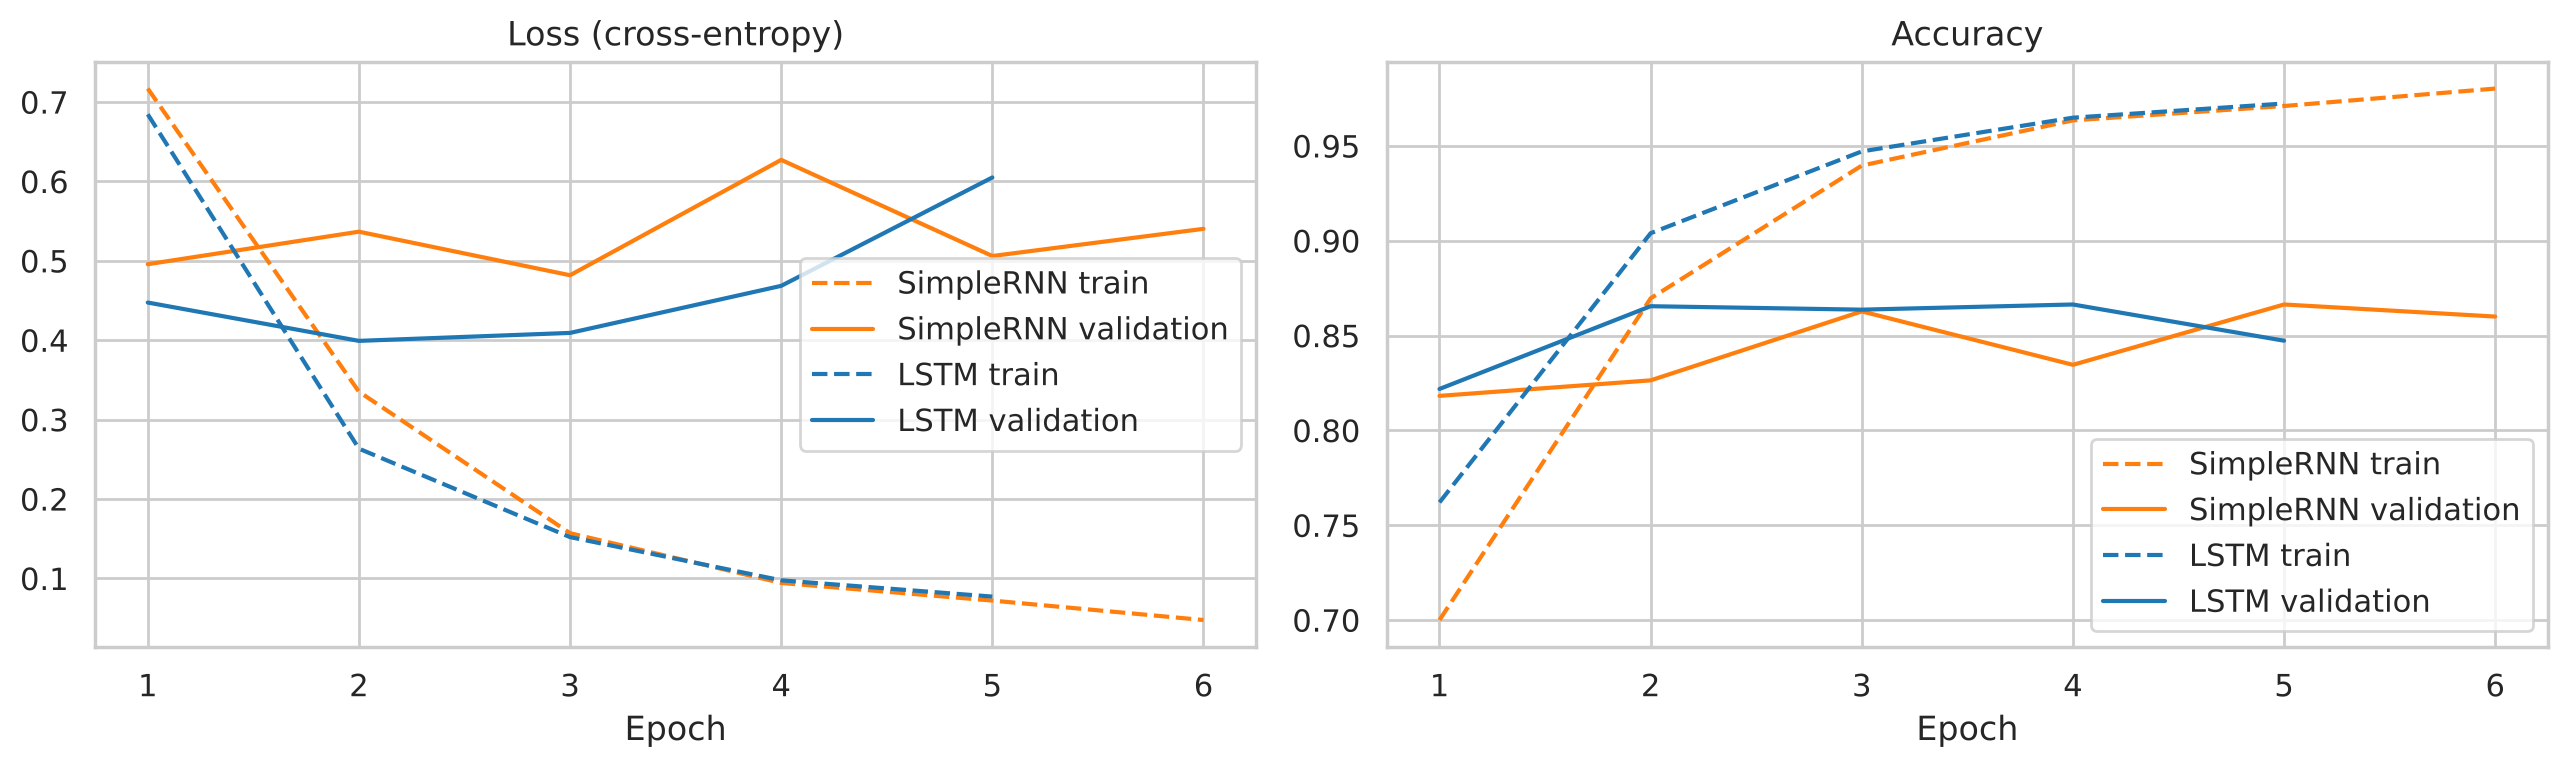

In [ ]:
# Learning curves: loss and accuracy per epoch
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h, color in [("SimpleRNN", rnn_history, "tab:orange"), ("LSTM", lstm_history, "tab:blue")]:
    ep = np.arange(1, len(h.history["loss"]) + 1)   # epochs counted from 1
    axes[0].plot(ep, h.history["loss"], color=color, linestyle="--", label=f"{name} train")
    axes[0].plot(ep, h.history["val_loss"], color=color, label=f"{name} validation")
    axes[1].plot(ep, h.history["accuracy"], color=color, linestyle="--", label=f"{name} train")
    axes[1].plot(ep, h.history["val_accuracy"], color=color, label=f"{name} validation")
axes[0].set_title("Loss (cross-entropy)"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Evaluation on the test set

The test set (1,260 reviews) was never used for training or for early stopping, so it shows how the models would do on new reviews.

In [ ]:
def evaluate(model, name):
    probs = model.predict(X_test, verbose=0)
    pred = probs.argmax(axis=1)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    print(f"===== {name} =====")
    print(f"Accuracy: {acc:.3f} | Macro F1: {f1:.3f}")
    print(classification_report(y_test, pred, target_names=ORDER, digits=3))
    return pred, acc, f1

rnn_pred, rnn_acc, rnn_f1 = evaluate(rnn_model, "SimpleRNN")
lstm_pred, lstm_acc, lstm_f1 = evaluate(lstm_model, "LSTM")

===== SimpleRNN =====
Accuracy: 0.858 | Macro F1: 0.815
              precision    recall  f1-score   support

    negative      0.789     0.863     0.824       394
     neutral      0.646     0.794     0.712       131
    positive      0.954     0.867     0.908       735

    accuracy                          0.858      1260
   macro avg      0.796     0.841     0.815      1260
weighted avg      0.870     0.858     0.861      1260



===== LSTM =====
Accuracy: 0.871 | Macro F1: 0.841
              precision    recall  f1-score   support

    negative      0.815     0.848     0.831       394
     neutral      0.704     0.870     0.778       131
    positive      0.945     0.884     0.914       735

    accuracy                          0.871      1260
   macro avg      0.821     0.867     0.841      1260
weighted avg      0.879     0.871     0.874      1260



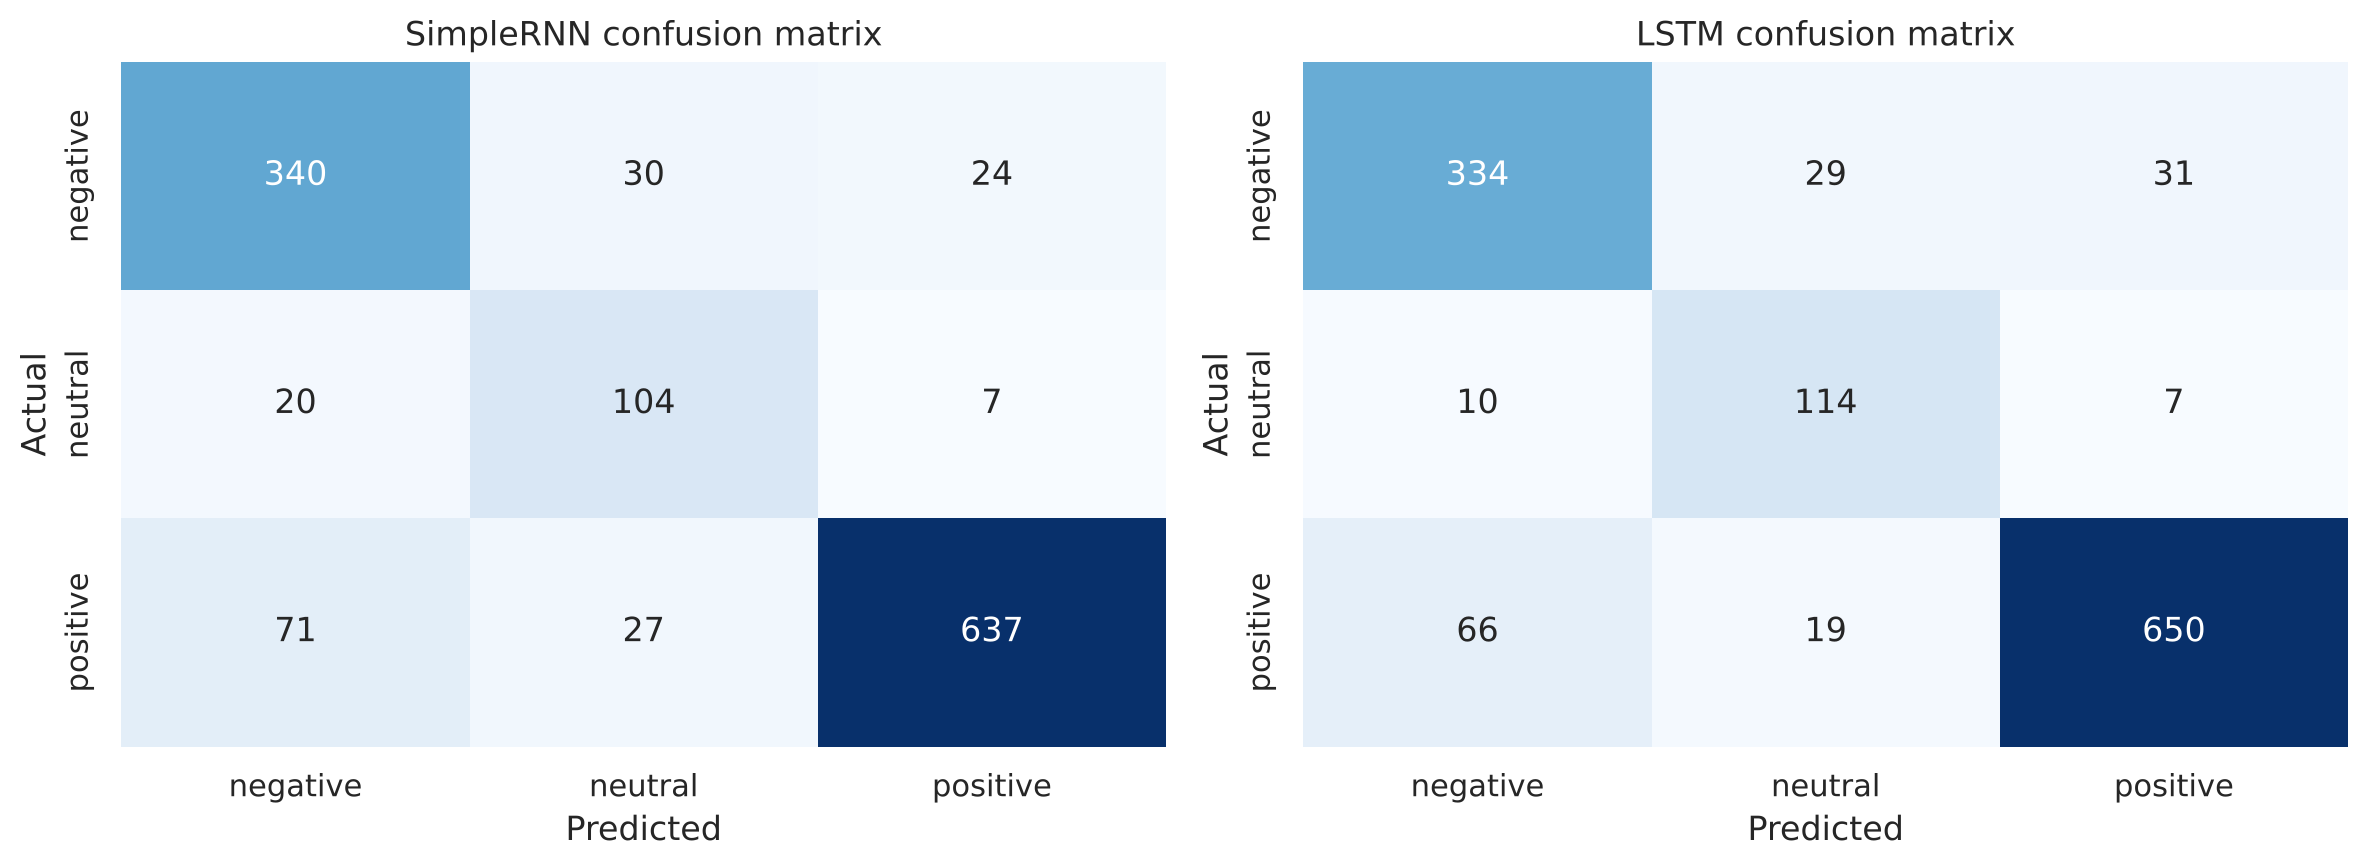

,Model,Test accuracy,Test macro F1,Epochs trained
0,SimpleRNN,0.858,0.815,6
1,LSTM,0.871,0.841,5


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, name in [(axes[0], rnn_pred, "SimpleRNN"), (axes[1], lstm_pred, "LSTM")]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ORDER, yticklabels=ORDER, ax=ax, cbar=False)
    ax.set_title(f"{name} confusion matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Model": ["SimpleRNN", "LSTM"],
    "Test accuracy": [rnn_acc, lstm_acc],
    "Test macro F1": [rnn_f1, lstm_f1],
    "Epochs trained": [len(rnn_history.history["loss"]), len(lstm_history.history["loss"])],
}).round(3)
summary

## 8. Short reviews vs long reviews

The theory says a SimpleRNN struggles to learn from words far back in a sequence, because during BPTT the gradient is multiplied by $\mathrm{diag}(1 - h_j^2)\,W_{hh}$ at every step back and can shrink exponentially (the vanishing gradient). The LSTM's additive cell state lets it learn to keep information for longer.

If that matters for this task, the LSTM's advantage should be **largest on long reviews**. We split the test reviews into three length groups and compare the accuracy of both models in each group.

,reviews,SimpleRNN,LSTM
length_group,,,
short (≤ 15 words),309,0.790,0.812
medium (16–35 words),485,0.870,0.874
long (> 35 words),466,0.891,0.908


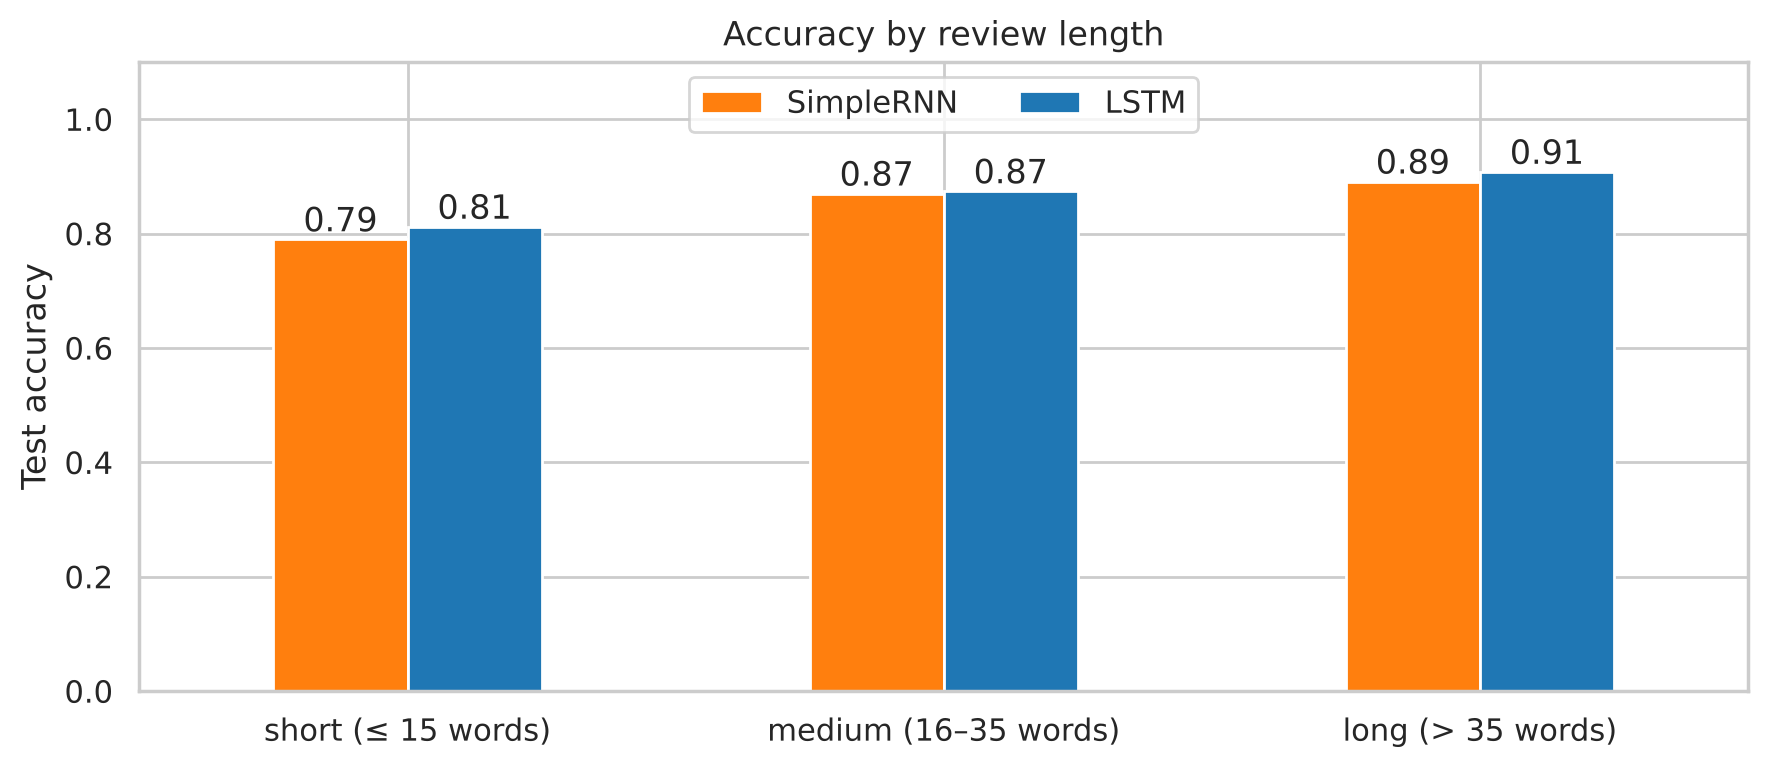

In [ ]:
bins = [0, 15, 35, 10_000]
labels = ["short (≤ 15 words)", "medium (16–35 words)", "long (> 35 words)"]
test_eval = test_df.assign(
    length_group=pd.cut(test_df["n_words"], bins=bins, labels=labels),
    rnn_correct=(rnn_pred == y_test),
    lstm_correct=(lstm_pred == y_test),
)
by_length = (test_eval.groupby("length_group", observed=True)
             .agg(reviews=("text", "size"), SimpleRNN=("rnn_correct", "mean"), LSTM=("lstm_correct", "mean"))
             .round(3))
display(by_length)

ax = by_length[["SimpleRNN", "LSTM"]].plot(kind="bar", figsize=(9, 4), color=["tab:orange", "tab:blue"], rot=0)
ax.set_ylabel("Test accuracy"); ax.set_ylim(0, 1.1); ax.set_xlabel("")
ax.legend(loc="upper center", ncol=2)
ax.set_title("Accuracy by review length")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.tight_layout()
plt.show()

## 9. Trying the model on new reviews

Below are new sentences written for this demo (not in the dataset). Look at pairs that differ by one word, such as *enak* / *tidak enak*: the model must use **word order and context** to get them right.

In [ ]:
new_reviews = [
    "makanannya enak sekali dan pelayanannya ramah",
    "makanannya tidak enak dan pelayanannya lambat",
    "tempatnya bagus tapi harganya terlalu mahal dan pelayannya tidak ramah",
    "aplikasi ini sangat membantu , pengiriman cepat dan barang sesuai pesanan",
    "aplikasinya sering error dan tidak bisa login , sangat mengecewakan",
    "besok rapat akan dimulai pukul sembilan pagi di kantor",
]

def predict(texts, model):
    probs = model.predict(vectorizer(np.array([normalize(t) for t in texts])), verbose=0)
    return [(id2label[p.argmax()], p.max()) for p in probs]

rows = []
for text, (r_lab, r_p), (l_lab, l_p) in zip(new_reviews, predict(new_reviews, rnn_model), predict(new_reviews, lstm_model)):
    rows.append({"review": text, "SimpleRNN": f"{r_lab} ({r_p:.0%})", "LSTM": f"{l_lab} ({l_p:.0%})"})
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows)

,review,SimpleRNN,LSTM
0,makanannya enak sekali dan pelayanannya ramah,positive (92%),positive (87%)
1,makanannya tidak enak dan pelayanannya lambat,negative (63%),negative (67%)
2,tempatnya bagus tapi harganya terlalu mahal dan pelayannya tidak ramah,negative (68%),negative (56%)
3,"aplikasi ini sangat membantu , pengiriman cepat dan barang sesuai pesanan",positive (82%),positive (78%)
4,"aplikasinya sering error dan tidak bisa login , sangat mengecewakan",negative (76%),negative (88%)
5,besok rapat akan dimulai pukul sembilan pagi di kantor,neutral (92%),neutral (97%)


In [ ]:
# Try your own review here
my_review = "pelayanannya cepat tapi makanannya dingin"
for name, model in [("SimpleRNN", rnn_model), ("LSTM", lstm_model)]:
    label, p = predict([my_review], model)[0]
    print(f"{name:9s} → {label} ({p:.0%})")

SimpleRNN → negative (53%)
LSTM      → negative (47%)


## 10. Conclusion

**What we did:** we framed Indonesian review sentiment as a many-to-one sequence problem, used the public SmSA dataset (12,260 labelled reviews and comments), turned each review into a sequence of word vectors, and trained a SimpleRNN and an LSTM with the same settings.

**Results in our run** (CPU, seed 42; your numbers in Colab may differ slightly):

| Model | Test accuracy | Test macro F1 | Neutral-class F1 | Best validation loss |
|---|---|---|---|---|
| SimpleRNN | 0.858 | 0.815 | 0.712 | 0.482 |
| LSTM | **0.871** | **0.841** | **0.778** | **0.399** |

**What the results show:**
1. **Both recurrent models work well**, reaching about 86–87% accuracy on reviews they never saw. Reading the words in order with a hidden state is enough to capture patterns like *tidak enak* (negative) vs *enak* (positive).
2. **The LSTM is better on every metric**, and most clearly on the hard, rare **neutral** class (F1 0.712 → 0.778). Its gates let it decide what to remember and what to forget, instead of overwriting the whole hidden state at every word.
3. **Short vs long reviews:** the LSTM is ahead in all three length groups (short 0.812 vs 0.790, medium 0.874 vs 0.870, long 0.908 vs 0.891), but the gap does **not** clearly grow with length. In this dataset reviews are at most 72 words, and long reviews repeat their opinion in many places, so a model does not need to remember the first word to get the label right. The vanishing gradient matters more for much longer sequences, such as whole documents or long time series.
4. **The theory matches the code:** the parameter counts match the formulas exactly (LSTM = 4 × SimpleRNN), the cost function is cross-entropy, and `fit()` trains the shared weights with Backpropagation Through Time. Both models start to overfit after 2–3 epochs (training accuracy keeps rising while validation loss goes up), which early stopping handles.

The difference between the two models comes from a single training run on 1,260 test reviews, so it is modest. Repeating the experiment with several random seeds would show how stable it is.

**Limitations and next steps**
- The models learn word vectors from only ~10,000 reviews. Pre-trained Indonesian embeddings (e.g. fastText) or a pre-trained Transformer such as **IndoBERT** would understand rare words and slang better.
- A **Bidirectional LSTM** reads the review in both directions and often adds a few points of accuracy.
- Reviews longer than `MAX_LEN` words are cut, so the end of very long reviews is not seen.
- Results can change slightly between runs and between CPU and GPU, even with a fixed seed.

**References**
- Wilie, B., et al. (2020). *IndoNLU: Benchmark and Resources for Evaluating Indonesian Natural Language Understanding.* AACL-IJCNLP 2020. https://github.com/IndoNLP/indonlu
- Purwarianti, A., & Crisdayanti, I. A. P. A. (2019). *Improving Bi-LSTM Performance for Indonesian Sentiment Analysis Using Paragraph Vector.* ICAICTA 2019.
- Hochreiter, S., & Schmidhuber, J. (1997). *Long Short-Term Memory.* Neural Computation, 9(8), 1735–1780.